# Transcript Analysis Helper

Interactively explore the transcript `.txt` files housed under `data/` using the helpers defined in `script.py`.


In [200]:
from pathlib import Path

import pandas as pd

from dataloader import TranscriptLoader

loader = TranscriptLoader()
print(f"Data directory: {loader.data_dir}")


Data directory: /Users/bentindal/Desktop/CognoSpeak/data


In [201]:
from file_validator import validate_file_naming, print_validation_report

# Check for files that don't follow naming convention
naming_issues = validate_file_naming(Path(loader.data_dir))
print_validation_report(naming_issues)


FILE NAMING CONVENTION CHECK

Accepted formats:
  - Process-XXX__PFT.txt or Process-XXX__SFT.txt (double underscore)
  - Process-XXX_PFT.txt or Process-XXX_SFT.txt (single underscore)
Files should be in directories: Process-rec-XXX/ or Process-test-XXX/

✅ All files follow the naming convention!


In [202]:
transcript_paths = loader.discover_transcript_files()
len(transcript_paths), transcript_paths[:5]


(125,
 [PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-006/Process-rec-006_SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-009/Process-rec-009__PFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-009/Process-rec-009__SFT.txt'),
  PosixPath('/Users/bentindal/Desktop/CognoSpeak/data/Process-rec-013/Process-rec-013_PFT.txt')])

In [203]:
example_path = transcript_paths[0]
example_df = loader.load_transcript(example_path)
example_df.head()


,start_time,end_time,token,recording,task,recording_number,source_path
0,1.277713,1.984534,Piper,Process-rec-006,PFT,6,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
1,2.174831,2.963208,Pencil,Process-rec-006,PFT,6,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
2,5.872045,6.90509,Personality,Process-rec-006,PFT,6,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
3,8.128432,8.699325,Plumbing,Process-rec-006,PFT,6,/Users/bentindal/Desktop/CognoSpeak/data/Proce...
4,9.759556,10.276078,Plumb,Process-rec-006,PFT,6,/Users/bentindal/Desktop/CognoSpeak/data/Proce...


In [204]:
frames = loader.load_all_transcripts(transcript_paths)
combined = loader.concatenate_transcripts(frames.values())
summary = loader.summarize_structure(combined)
summary.to_frame(name='value')


,value
rows,2257
recordings,64
tasks,"PFT, SFT"
start_time_range,"(0.0, 62.095093)"
end_time_range,"(0.317635, 62.690496)"
missing_values,0


In [205]:
metadata = loader.load_metadata()
metadata.head()


,recording,age,gender,diagnosis,MMSE,annotator,notes,recording_number
0,Process-rec-143,70.0,male,DEMENTIA,24.0,Madhu,"SFT: all good, something said at the end, can'...",143
1,Process-rec-091,73.0,female,DEMENTIA,20.0,Kevin,"SFT: good, repeated a couple words towards the...",91
2,Process-test-038,73.0,male,DEMENTIA,<NA>,Kevin,"SFT: good until end, noticeable pauses; PFT: n...",38
3,Process-rec-107,75.0,female,DEMENTIA,<NA>,Kevin,"SFT: good, noticeable pauses, repeated word; P...",107
4,Process-rec-040,77.0,male,DEMENTIA,<NA>,Kevin,"SFT: all good; PFT: poor, apologised for strug...",40


In [206]:
merged = loader.merge_with_metadata(combined, metadata)
merged[['recording', 'diagnosis']].drop_duplicates().head()


,recording,diagnosis
0,Process-rec-006,DEMENTIA
28,Process-rec-009,HC
75,Process-rec-013,MCI
127,Process-rec-014,MCI
167,Process-rec-015,MCI


In [207]:
# Optional: persist the combined dataset for downstream work
output_path = Path('combined_transcripts.parquet')
combined.to_parquet(output_path, index=False)
output_path


PosixPath('combined_transcripts.parquet')

In [208]:
from pathlib import Path
from pause_analyzer import analyze_pauses

# Generate pause_summary.csv if it doesn't exist
pause_summary_path = Path('pause_summary.csv')
if not pause_summary_path.exists():
    print("Generating pause_summary.csv...")
    analyze_pauses(Path(loader.data_dir), pause_summary_path)
    print(f"✓ Created {pause_summary_path}")
else:
    print(f"✓ {pause_summary_path} already exists")


Generating pause_summary.csv...
✓ Created pause_summary.csv


## Pause Metrics by Diagnosis

Merge the pause statistics from `pause_summary.csv` with the subject metadata to compare cohorts (Dementia, MCI, HC).


In [209]:
import matplotlib.pyplot as plt
import seaborn as sns

pause_summary = pd.read_csv('pause_summary.csv')
pause_summary['recording'] = pause_summary['transcript'].str.split('/').str[0]

pause_with_diag = pause_summary.merge(
    metadata.rename(columns={'anyon_IDs': 'recording'})[['recording', 'diagnosis']],
    on='recording',
    how='left'
)
pause_with_diag.dropna(subset=['diagnosis'], inplace=True)
pause_with_diag.head()


,transcript,token_count,pause_count,pause_mean,pause_median,pause_min,pause_max,pause_std,pause_total,recording,diagnosis
0,Process-rec-006/Process-rec-006_PFT.txt,18,17,2.535626,1.223342,0.190297,13.555324,3.487955,43.105637,Process-rec-006,DEMENTIA
1,Process-rec-006/Process-rec-006_SFT.txt,10,9,2.439959,1.364377,0.278641,8.438261,2.835415,21.959633,Process-rec-006,DEMENTIA
2,Process-rec-009/Process-rec-009__PFT.txt,26,25,1.384587,1.034487,0.188424,5.889187,1.277464,34.614670,Process-rec-009,HC
3,Process-rec-009/Process-rec-009__SFT.txt,21,20,2.125884,0.382095,0.071988,13.934447,3.760067,42.517689,Process-rec-009,HC
4,Process-rec-013/Process-rec-013_PFT.txt,25,24,1.672991,1.328717,0.129631,6.435419,1.656693,40.151791,Process-rec-013,MCI


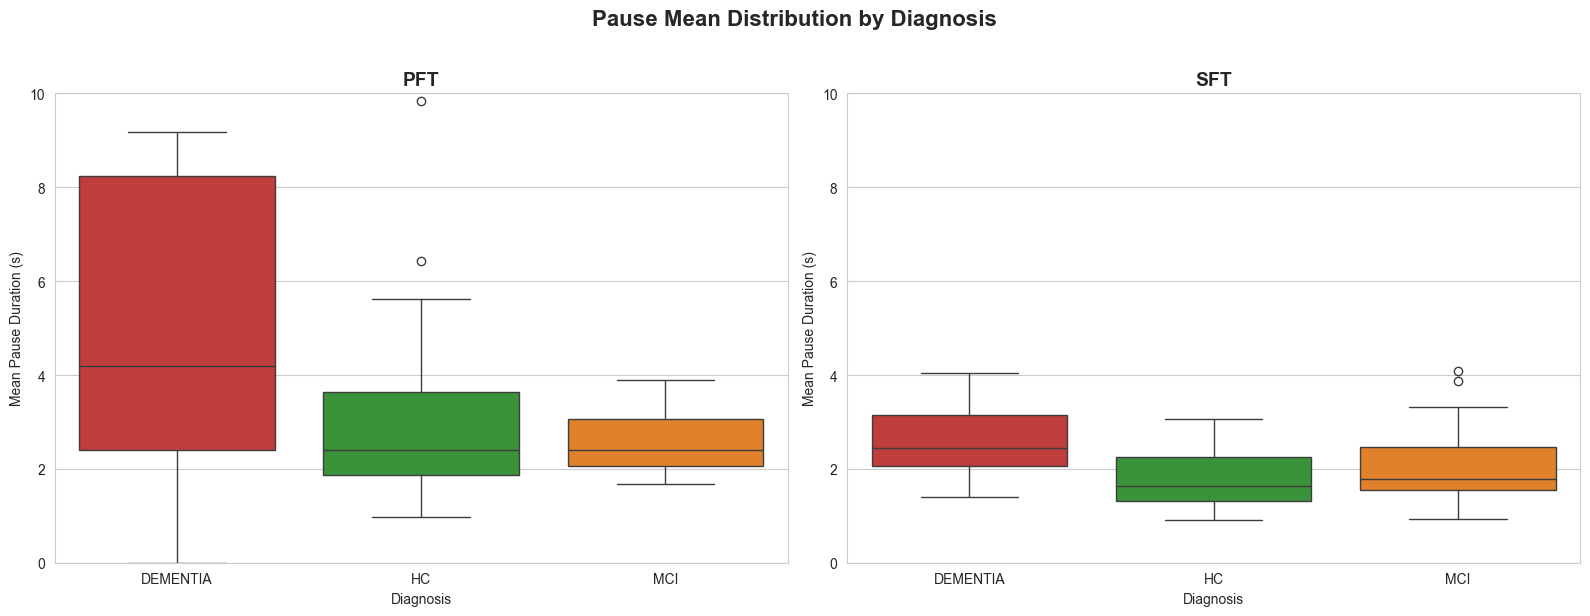


diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    12.0  4.735858  3.101849  2.407834  4.190905  8.247514
HC          28.0  3.153220  1.900890  1.863659  2.400012  3.635433
MCI         21.0  4.355900  8.558247  2.060845  2.399909  3.067956

diagnosis Statistics:
           count      mean       std       25%       50%       75%
diagnosis                                                         
DEMENTIA    15.0  2.640845  0.851390  2.060688  2.439959  3.140605
HC          28.0  1.730157  0.613255  1.310314  1.639390  2.248435
MCI         21.0  2.103499  0.946366  1.548553  1.781469  2.455798


In [210]:
import re
from plotting import plot_3class_comparison, print_descriptive_stats

# Convert diagnosis to categorical with desired order
pause_with_diag['diagnosis'] = pd.Categorical(
    pause_with_diag['diagnosis'],
    categories=['DEMENTIA', 'HC', 'MCI'],
    ordered=True
)

# Extract task (PFT/SFT) from transcript path
pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_3class_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'diagnosis')
print_descriptive_stats(sft_data, 'diagnosis')


## Statistical Tests: 3-Class Comparison

Two-tailed independent samples t-tests to compare means between diagnosis groups.


TWO-TAILED T-TESTS: PFT

DEMENTIA vs HC:
  t-statistic: 1.9826
  p-value: 0.0547
  Significant (p < 0.05): No 

DEMENTIA vs MCI:
  t-statistic: 0.1475
  p-value: 0.8837
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 0.7226
  p-value: 0.4735
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

DEMENTIA vs HC:
  t-statistic: 4.0446
  p-value: 0.0002
  Significant (p < 0.05): Yes *

DEMENTIA vs MCI:
  t-statistic: 1.7497
  p-value: 0.0892
  Significant (p < 0.05): No 

MCI vs HC:
  t-statistic: 1.6736
  p-value: 0.1009
  Significant (p < 0.05): No 


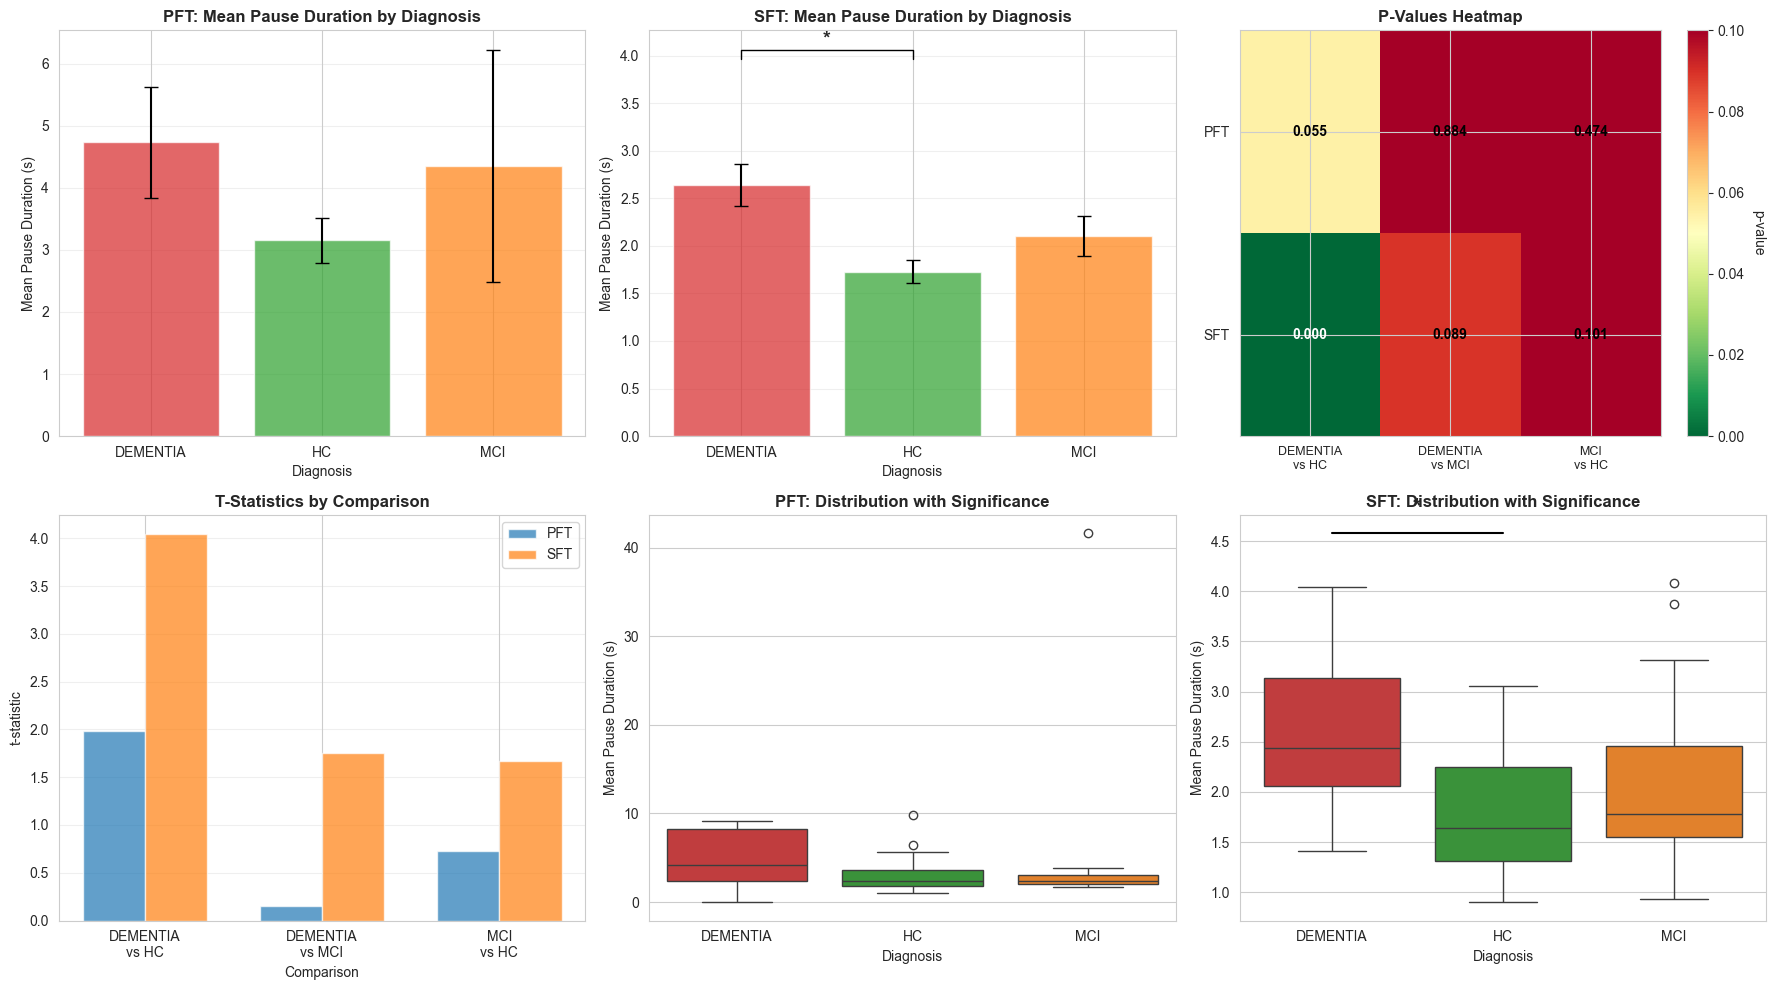


SUMMARY: Significant differences (p < 0.05) are marked with *


In [211]:
from statistical_tests import perform_3class_ttests, print_ttest_results, plot_3class_statistics

# Perform t-tests
test_results = perform_3class_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_3class_statistics(pft_data, sft_data, test_results)


## Healthy vs Non-Healthy by Task (PFT and SFT)

Compare Healthy vs Non-Healthy groups separately for PFT and SFT tasks.


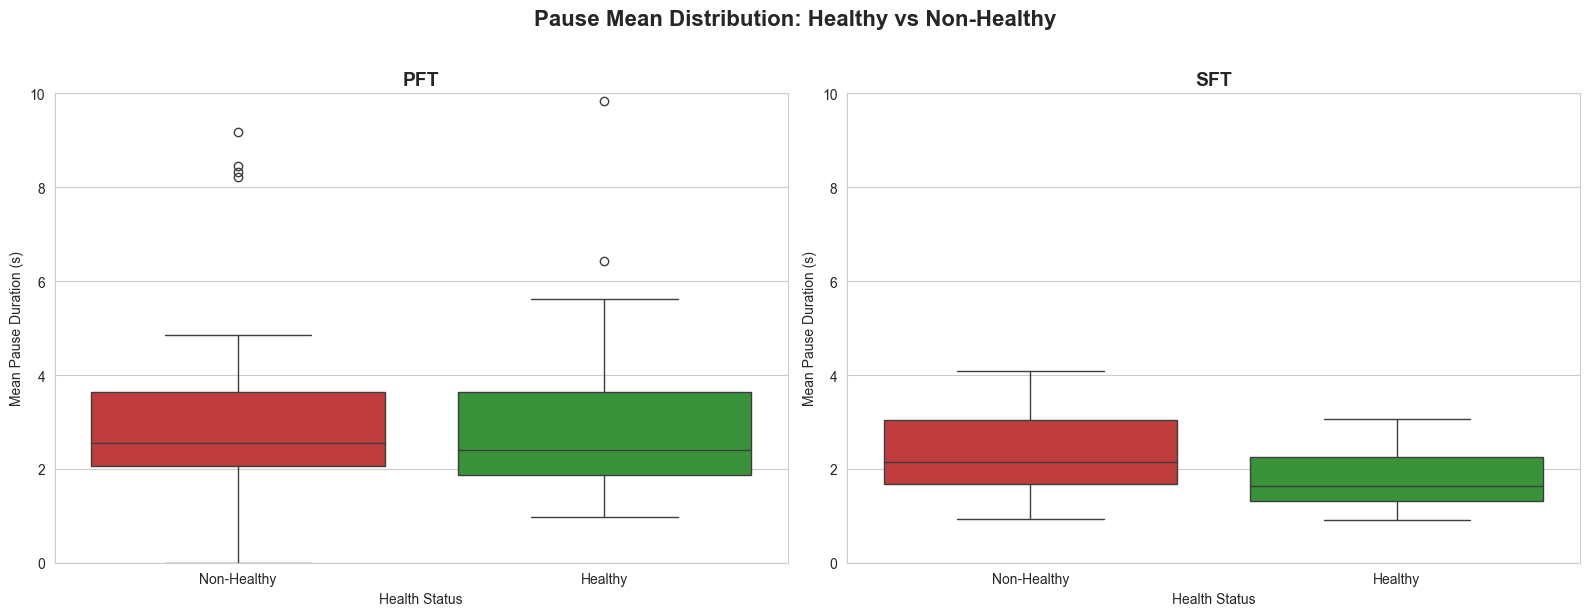


health_status Statistics:
               count      mean      std       25%       50%       75%
health_status                                                        
Non-Healthy     33.0  4.494067  7.00850  2.060845  2.555044  3.648021
Healthy         28.0  3.153220  1.90089  1.863659  2.400012  3.635433

health_status Statistics:
               count      mean       std       25%       50%       75%
health_status                                                         
Non-Healthy     36.0  2.327393  0.934830  1.669739  2.149098  3.049067
Healthy         28.0  1.730157  0.613255  1.310314  1.639390  2.248435


In [212]:
import re
from plotting import plot_binary_comparison, print_descriptive_stats

# Extract task (PFT/SFT) from transcript path (if not already done)
if 'task' not in pause_with_diag.columns:
    pause_with_diag['task'] = pause_with_diag['transcript'].str.extract(r'([PS]FT)', flags=re.IGNORECASE)[0].str.upper()

# Filter to only PFT and SFT tasks
pause_with_diag_filtered = pause_with_diag[pause_with_diag['task'].isin(['PFT', 'SFT'])].copy()

# Create health_status if not already created
if 'health_status' not in pause_with_diag_filtered.columns:
    pause_with_diag_filtered['health_status'] = pause_with_diag_filtered['diagnosis'].apply(
        lambda x: 'Non-Healthy' if x in ['DEMENTIA', 'MCI'] else 'Healthy'
    )
    pause_with_diag_filtered['health_status'] = pd.Categorical(
        pause_with_diag_filtered['health_status'],
        categories=['Non-Healthy', 'Healthy'],
        ordered=True
    )

# Prepare data
pft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'PFT']
sft_data = pause_with_diag_filtered[pause_with_diag_filtered['task'] == 'SFT']

# Plot comparison
plot_binary_comparison(pft_data, sft_data)

# Print descriptive statistics
print_descriptive_stats(pft_data, 'health_status')
print_descriptive_stats(sft_data, 'health_status')


## Statistical Tests: Binary Comparison (Healthy vs Non-Healthy)

Two-tailed independent samples t-tests to compare means between Healthy and Non-Healthy groups.


TWO-TAILED T-TESTS: PFT

Healthy vs Non-Healthy:
  t-statistic: -0.9811
  p-value: 0.3306
  Significant (p < 0.05): No 
TWO-TAILED T-TESTS: SFT

Healthy vs Non-Healthy:
  t-statistic: -2.9239
  p-value: 0.0048
  Significant (p < 0.05): Yes *


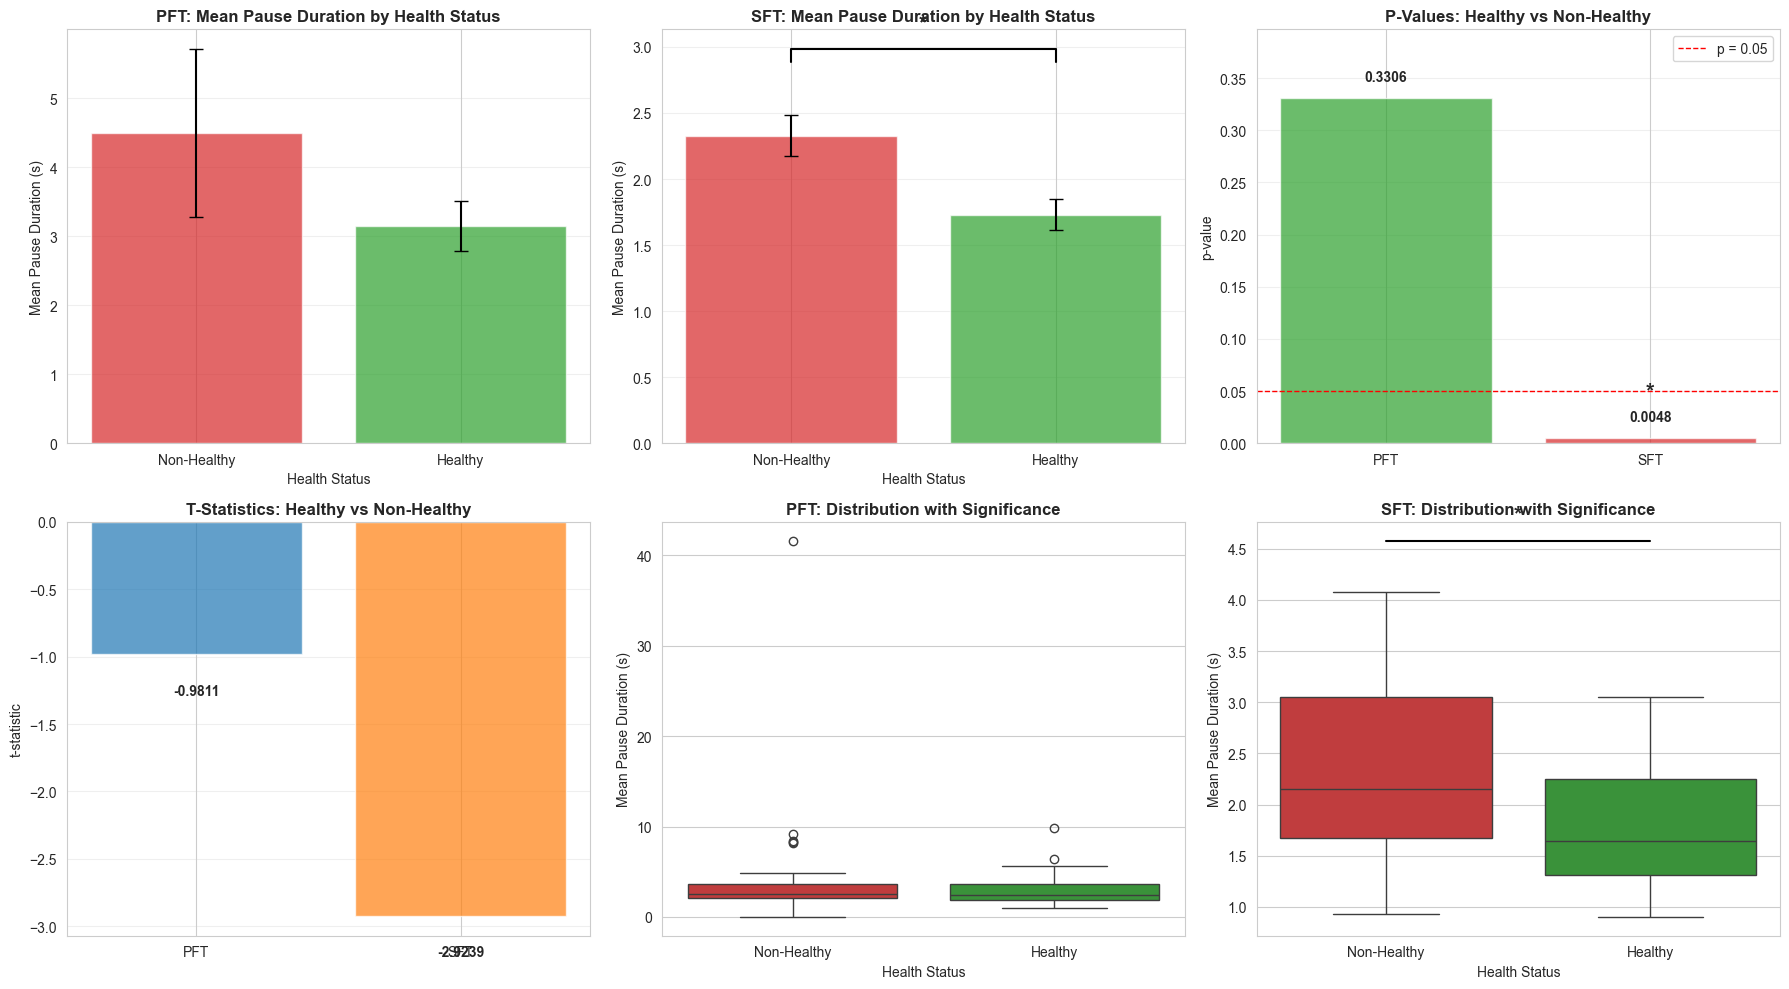


SUMMARY: Significant differences (p < 0.05) are marked with *


In [213]:
from statistical_tests import perform_binary_ttests, print_ttest_results, plot_binary_statistics

# Perform t-tests
test_results = perform_binary_ttests(pft_data, sft_data)

# Print results
print_ttest_results(test_results)

# Create visualizations
plot_binary_statistics(pft_data, sft_data, test_results)


## Binary Classifier: Dementia vs Healthy

Build a binary classifier using SFT pause metrics to distinguish Dementia (1) from Healthy (0). We'll use 5-fold cross-validation and visualize the results with a confusion matrix.


In [214]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

from binary_classifier import build_feature_dataset, get_classifier

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 8)


In [215]:
# Build feature dataset using SFT pause metrics only
features_df = build_feature_dataset(
    data_dir=loader.data_dir,
    metadata_path=loader.metadata_path,
    include_pft=False  # Use SFT only
)

print(f"Loaded {len(features_df)} recordings")
print(f"  - Dementia: {sum(features_df['label'] == 1)}")
print(f"  - Healthy (HC): {sum(features_df['label'] == 0)}")

# Prepare features and labels
feature_cols = [col for col in features_df.columns if col.startswith('sft_')]
X = features_df[feature_cols].fillna(0)
y = features_df['label']

print(f"\nUsing {len(feature_cols)} SFT pause features:")
for col in feature_cols:
    print(f"  - {col}")


Loaded 43 recordings
  - Dementia: 15
  - Healthy (HC): 28

Using 7 SFT pause features:
  - sft_pause_count
  - sft_pause_mean
  - sft_pause_median
  - sft_pause_min
  - sft_pause_max
  - sft_pause_std
  - sft_pause_total


In [216]:
# Perform 5-fold cross-validation and collect predictions for confusion matrix
k_folds = 5
cv = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=24)
classifier = get_classifier('logistic')

# Store all predictions and true labels across folds
all_y_true = []
all_y_pred = []
fold_accuracies = []

print(f"Running {k_folds}-fold cross-validation...\n")

for fold_idx, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    
    # Train and predict
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    
    # Store predictions
    all_y_true.extend(y_test.values)
    all_y_pred.extend(y_pred)
    
    # Calculate fold accuracy
    fold_acc = (y_pred == y_test.values).mean()
    fold_accuracies.append(fold_acc)
    
    print(f"Fold {fold_idx}: Accuracy = {fold_acc:.4f}")

print(f"\nMean accuracy across {k_folds} folds: {np.mean(fold_accuracies):.4f} ± {np.std(fold_accuracies):.4f}")


Running 5-fold cross-validation...

Fold 1: Accuracy = 1.0000
Fold 2: Accuracy = 0.8889
Fold 3: Accuracy = 0.7778
Fold 4: Accuracy = 0.8750
Fold 5: Accuracy = 0.6250

Mean accuracy across 5 folds: 0.8333 ± 0.1258


In [217]:
# Generate confusion matrix
cm = confusion_matrix(all_y_true, all_y_pred)

# Print classification report
print("Classification Report (aggregated across all folds):")
print("=" * 60)
print(classification_report(all_y_true, all_y_pred, 
                          target_names=['Healthy (HC)', 'Dementia']))
print("=" * 60)


Classification Report (aggregated across all folds):
              precision    recall  f1-score   support

Healthy (HC)       0.84      0.93      0.88        28
    Dementia       0.83      0.67      0.74        15

    accuracy                           0.84        43
   macro avg       0.84      0.80      0.81        43
weighted avg       0.84      0.84      0.83        43



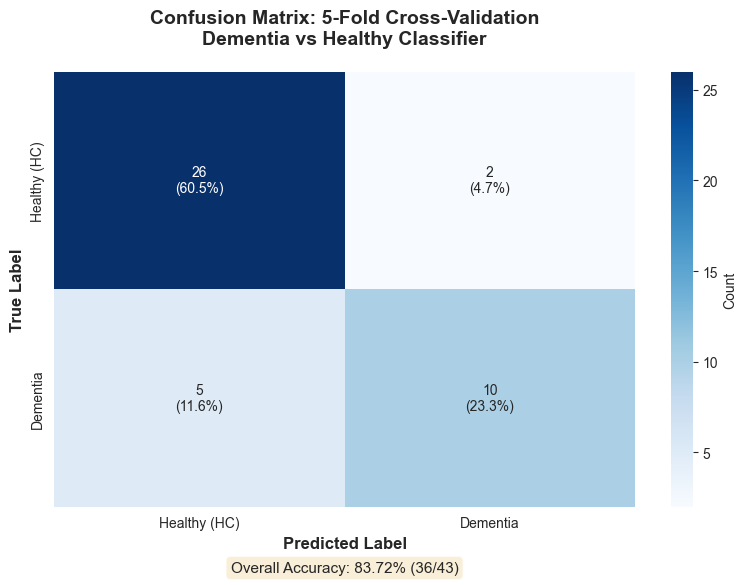

In [218]:
# Plot confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

# Calculate percentages of total sample
total_samples = cm.sum()
cm_percent_total = cm.astype('float') / total_samples * 100

# Create annotation labels with both count and percentage of total
annot_labels = []
for i in range(len(cm)):
    row = []
    for j in range(len(cm)):
        count = cm[i, j]
        percent = cm_percent_total[i, j]
        row.append(f'{count}\n({percent:.1f}%)')
    annot_labels.append(row)

# Create heatmap with custom annotations
sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', 
            xticklabels=['Healthy (HC)', 'Dementia'],
            yticklabels=['Healthy (HC)', 'Dementia'],
            cbar_kws={'label': 'Count'},
            ax=ax)

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix: 5-Fold Cross-Validation\nDementia vs Healthy Classifier', 
             fontsize=14, fontweight='bold', pad=20)

# Add accuracy text
total = cm.sum()
correct = np.trace(cm)
accuracy = correct / total
ax.text(0.5, -0.15, f'Overall Accuracy: {accuracy*100:.2f}% ({correct}/{total})',
        transform=ax.transAxes, ha='center', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()
